# Fine-tuning BERT (dbmdz/bert-base-french-europeana-cased) pour la NER Départ/Arrivée

Ce notebook entraîne le modèle BERT français sur le dataset `dataset_input.txt` / `dataset_output.txt`.

- **Labels** : O, B-DEP, I-DEP, B-ARR, I-ARR
- **10 epochs**, courbe F1 par epoch, courbes ROC multiclasses.

## 1. Imports et configuration

In [8]:
# Colab uniquement : installer TensorFlow + transformers avec support TF
# Les versions récentes de transformers (4.46+) ont retiré TFBert, on fixe 4.43
import sys
import subprocess
if 'google.colab' in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tensorflow", "transformers==4.43.0"], check=True)
    print("Installation terminée. Redémarrez le runtime (Runtime → Restart session), puis réexécutez le notebook.")
else:
    print("Pas sous Colab : utilisez votre environnement local (tensorflow + transformers).")

Installation terminée. Redémarrez le runtime (Runtime → Restart session), puis réexécutez le notebook.


In [9]:
import os
import warnings
import numpy as np

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import tensorflow as tf
tf.get_logger().setLevel('ERROR')
warnings.filterwarnings('ignore')

from transformers import BertTokenizerFast, TFBertForTokenClassification
from sklearn.preprocessing import LabelEncoder

from bert_ner_utils import (
    encode_data,
    get_metrics,
    get_ROC_curve,
    UNIQUE_LABELS,
)

# Chemins (notebook dans model/ALEXANDRE)
_dir = os.getcwd()
if 'ALEXANDRE' in _dir:
    DATASET_DIR = os.path.normpath(os.path.join(_dir, '..', '..', 'dataset'))
else:
    DATASET_DIR = os.path.normpath(os.path.join(_dir, '/content'))

INPUT_PATH = os.path.join(DATASET_DIR, 'dataset_input.txt')
OUTPUT_PATH = os.path.join(DATASET_DIR, 'dataset_output.txt')
MODEL_NAME = 'dbmdz/bert-base-french-europeana-cased'
SAVE_DIR = os.path.join(_dir, 'bert_europeana_ner')
MAX_LENGTH = 64
EPOCHS = 10
BATCH_SIZE = 16
VALIDATION_SPLIT = 0.1
RANDOM_STATE = 42

print("Dataset dir:", DATASET_DIR)
print("Save dir:", SAVE_DIR)

Dataset dir: /content
Save dir: /content/bert_europeana_ner


## 2. Chargement du dataset

In [10]:
def load_dataset(limit=None):
    """Charge (phrase, depart, arrivee) depuis dataset_input.txt et dataset_output.txt."""
    data = []
    with open(INPUT_PATH, 'r', encoding='utf-8') as f_in, \
         open(OUTPUT_PATH, 'r', encoding='utf-8') as f_out:
        count = 0
        for line_in, line_out in zip(f_in, f_out):
            if limit and count >= limit:
                break
            parts_in = line_in.strip().split(',', 1)
            parts_out = line_out.strip().split(',')
            if len(parts_in) < 2 or len(parts_out) < 2:
                continue
            phrase = parts_in[1]
            depart = parts_out[1].strip() if len(parts_out) > 1 else ''
            arrivee = parts_out[2].strip() if len(parts_out) > 2 else ''
            if depart == 'INVALID' or not depart or not arrivee:
                continue
            data.append({'phrase': phrase, 'depart': depart, 'arrivee': arrivee})
            count += 1
    return data


if not os.path.exists(INPUT_PATH) or not os.path.exists(OUTPUT_PATH):
    raise FileNotFoundError(f"Dataset not found: {INPUT_PATH} / {OUTPUT_PATH}")

data = load_dataset(limit=None)
np.random.seed(RANDOM_STATE)
np.random.shuffle(data)
print(f"Loaded {len(data)} samples")

Loaded 56000 samples


## 3. Labels et encodage

In [11]:
print("Labels: ['O', 'B-DEP', 'I-DEP', 'B-ARR', 'I-ARR']")
label_encoder = LabelEncoder()
label_encoder.fit(UNIQUE_LABELS)
print("Mapping:", {label: idx for idx, label in enumerate(label_encoder.classes_)})

tokenizer = BertTokenizerFast.from_pretrained(MODEL_NAME)

print("\nEncoding data...")
encodings, labels = encode_data(data, tokenizer, label_encoder, max_length=MAX_LENGTH, verbose=True)

Labels: ['O', 'B-DEP', 'I-DEP', 'B-ARR', 'I-ARR']
Mapping: {np.str_('B-ARR'): 0, np.str_('B-DEP'): 1, np.str_('I-ARR'): 2, np.str_('I-DEP'): 3, np.str_('O'): 4}


tokenizer_config.json:   0%|          | 0.00/83.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/420 [00:00<?, ?B/s]


Encoding data...

---> Ligne 1
- Original sentence:  comment puis-je aller de farges à neuville-les-dames
- Encoded tokens:  ['[CLS]', 'comment', 'puis', '-', 'je', 'aller', 'de', 'far', '##ges', 'à', 'neu', '##ville', '-', 'les', '-', 'dames', '[SEP]', '[PAD]', '[PAD]', '[PAD]']...
- Labels after encoding the entities:  [np.str_('O'), np.str_('O'), np.str_('O'), np.str_('O'), np.str_('O'), np.str_('O'), np.str_('O'), np.str_('B-DEP'), np.str_('I-DEP'), np.str_('O'), np.str_('B-ARR'), np.str_('I-ARR'), np.str_('I-ARR'), np.str_('I-ARR'), np.str_('I-ARR'), np.str_('I-ARR'), np.str_('O'), np.str_('O'), np.str_('O'), np.str_('O')]...
- Label IDs [4 4 4 4 4 4 4 1 3 4 0 2 2 2 2 2 4 4 4 4]...

---> Ligne 2
- Original sentence:  Quels horaires de villieu-loyes-mollon à archon
- Encoded tokens:  ['[CLS]', 'Quels', 'horaire', '##s', 'de', 'vill', '##ieu', '-', 'loy', '##es', '-', 'mol', '##lon', 'à', 'arch', '##on', '[SEP]', '[PAD]', '[PAD]', '[PAD]']...
- Labels after encoding the entities:  

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 4. Split train / validation

In [12]:
n = len(data)
n_val = int(n * VALIDATION_SPLIT)
n_train = n - n_val

train_enc = {k: v[:n_train] for k, v in encodings.items()}
train_lab = labels[:n_train]
val_enc = {k: v[n_train:] for k, v in encodings.items()}
val_lab = labels[n_train:]

print(f"Train: {n_train}, Val: {n_val}")

Train: 50400, Val: 5600


## 5. Modèle et callback F1

In [13]:
class F1Callback(tf.keras.callbacks.Callback):
    """Calcule F1 (weighted) sur le set de validation à chaque epoch."""
    def __init__(self, val_encodings, val_labels, label_encoder):
        super().__init__()
        self.val_encodings = val_encodings
        self.val_labels = val_labels
        self.label_encoder = label_encoder

    def on_epoch_end(self, epoch, logs=None):
        from sklearn.metrics import f1_score
        pred = self.model.predict(self.val_encodings, verbose=0)
        pred_ids = np.argmax(pred.logits, axis=-1).flatten()
        true_ids = self.val_labels.flatten()
        n_classes = len(self.label_encoder.classes_)
        mask = (true_ids >= 0) & (true_ids < n_classes)
        f1 = f1_score(true_ids[mask], pred_ids[mask], average='weighted', zero_division=0)
        logs = logs or {}
        logs['val_f1'] = float(f1)


model = TFBertForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_encoder.classes_),
)
print("Model loaded with", len(label_encoder.classes_), "labels")

optimizer = tf.keras.optimizers.legacy.Adam(learning_rate=5e-5)
loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])

f1_callback = F1Callback(val_enc, val_lab, label_encoder)

tf_model.h5:   0%|          | 0.00/545M [00:00<?, ?B/s]

All model checkpoint layers were used when initializing TFBertForTokenClassification.

Some layers of TFBertForTokenClassification were not initialized from the model checkpoint at dbmdz/bert-base-french-europeana-cased and are newly initialized: ['classifier']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model loaded with 5 labels


## 6. Entraînement (10 epochs)

In [14]:
history = model.fit(
    train_enc,
    train_lab,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(val_enc, val_lab),
    callbacks=[f1_callback],
)

Epoch 1/10
3150/3150 [==============================] - 757s 235ms/step - loss: 0.0122 - accuracy: 0.9961 - val_loss: 0.0017 - val_accuracy: 0.9995 - val_f1: 0.9995
Epoch 2/10
3150/3150 [==============================] - 755s 240ms/step - loss: 0.0017 - accuracy: 0.9995 - val_loss: 0.0013 - val_accuracy: 0.9997 - val_f1: 0.9997
Epoch 3/10
3150/3150 [==============================] - 736s 234ms/step - loss: 0.0013 - accuracy: 0.9997 - val_loss: 7.9797e-04 - val_accuracy: 0.9998 - val_f1: 0.9998
Epoch 4/10
3150/3150 [==============================] - 735s 233ms/step - loss: 0.0011 - accuracy: 0.9998 - val_loss: 0.0016 - val_accuracy: 0.9997 - val_f1: 0.9997
Epoch 5/10
3150/3150 [==============================] - 735s 233ms/step - loss: 0.0011 - accuracy: 0.9997 - val_loss: 2.2196e-04 - val_accuracy: 0.9999 - val_f1: 0.9999
Epoch 6/10
3150/3150 [==============================] - 735s 233ms/step - loss: 8.6785e-04 - accuracy: 0.9998 - val_loss: 5.7903e-04 - val_accuracy: 0.9999 - val_f1: 0

## 7. Sauvegarde du modèle

In [15]:
os.makedirs(SAVE_DIR, exist_ok=True)
model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
print("Model saved to:", os.path.abspath(SAVE_DIR))

Model saved to: /content/bert_europeana_ner


## 8. Évaluation et métriques

175/175 [==============================] - 30s 146ms/step - loss: 0.0012 - accuracy: 0.9997
Evaluation (loss, accuracy): [0.0012377661187201738, 0.999729335308075]
175/175 [==============================] - 23s 129ms/step
Confusion Matrix %:
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]

Confusion Matrix:
[[  4695      0      0      1      8]
 [     0   4595      0      0      3]
 [     0      0  13297      3     51]
 [     0      0      0  13202     12]
 [     2      2      8      7 322514]]

Classification Report:
              precision    recall  f1-score   support

       B-ARR       1.00      1.00      1.00      4704
       B-DEP       1.00      1.00      1.00      4598
       I-ARR       1.00      1.00      1.00     13351
       I-DEP       1.00      1.00      1.00     13214
           O       1.00      1.00      1.00    322533

    accuracy                           1.00    358400
   macro avg       1.00      1.00      1.00    358400

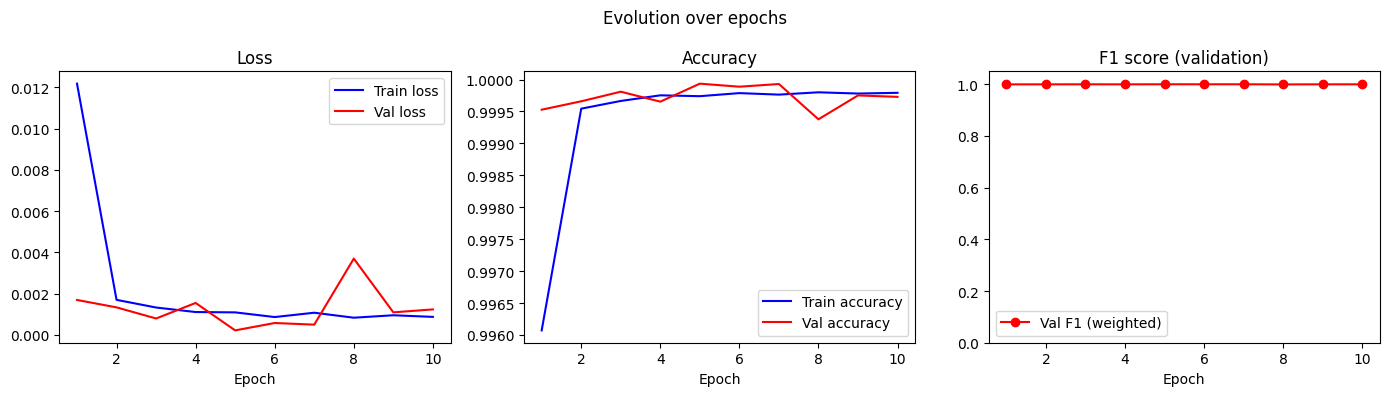

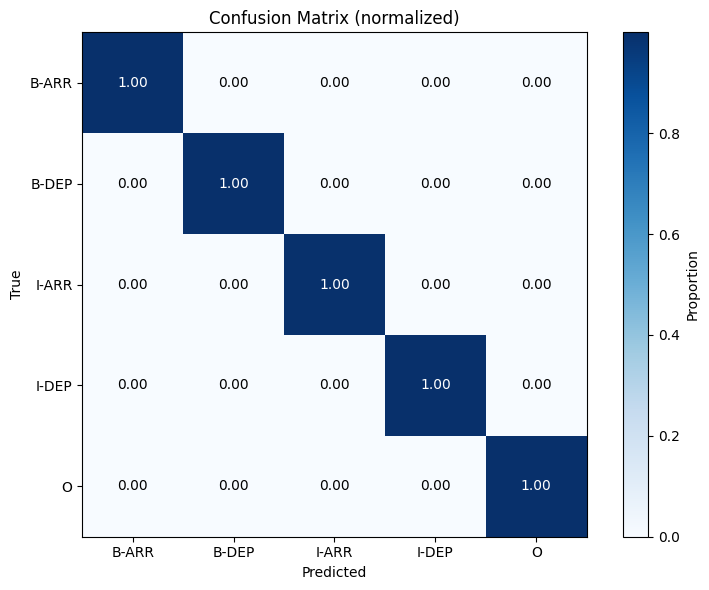

In [16]:
eval_res = model.evaluate(val_enc, val_lab)
print("Evaluation (loss, accuracy):", eval_res)

test_predictions = model.predict(val_enc)
pred_labels = np.argmax(test_predictions.logits, axis=-1).flatten()
true_labels_flat = val_lab.flatten()

get_metrics(
    true_labels=true_labels_flat,
    predicted_labels=pred_labels,
    unique_labels=UNIQUE_LABELS,
    history=history,
    label_encoder=label_encoder,
)

## 9. Courbe ROC multiclasses

In [ ]:
get_ROC_curve(
    true_labels=val_lab,
    logits=test_predictions.logits,
    unique_labels=UNIQUE_LABELS,
    label_encoder=label_encoder,
)

## 10. Courbe F1 par epoch

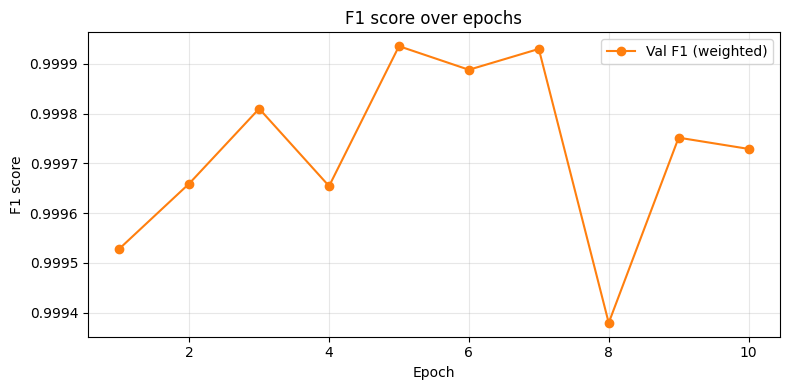

F1 per epoch: [0.9995, 0.9997, 0.9998, 0.9997, 0.9999, 0.9999, 0.9999, 0.9994, 0.9998, 0.9997]


In [18]:
import matplotlib.pyplot as plt

if 'val_f1' in history.history:
    plt.figure(figsize=(8, 4))
    plt.plot(range(1, EPOCHS + 1), history.history['val_f1'], 'o-', color='C1', label='Val F1 (weighted)')
    plt.xlabel('Epoch')
    plt.ylabel('F1 score')
    plt.title('F1 score over epochs')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    print("F1 per epoch:", [round(x, 4) for x in history.history['val_f1']])
else:
    print("No val_f1 in history.")

In [19]:
import sys
import shutil

# Créer une archive ZIP du dossier du modèle
zip_name = "bert_europeana_ner.zip"
if os.path.exists(SAVE_DIR):
    shutil.make_archive(zip_name.replace(".zip", ""), "zip", os.path.dirname(SAVE_DIR), os.path.basename(SAVE_DIR))
    print("Archive créée:", zip_name)

    # Sur Colab : téléchargement direct
    if "google.colab" in sys.modules:
        from google.colab import files
        files.download(zip_name)
        print("Téléchargement lancé : enregistrez le fichier sur votre disque.")
    else:
        print("Pas sous Colab. Le modèle est déjà dans:", os.path.abspath(SAVE_DIR))
        print("Archive disponible ici:", os.path.abspath(zip_name))
else:
    print("Le dossier du modèle n'existe pas. Exécutez d'abord les cellules d'entraînement et de sauvegarde.")

Archive créée: bert_europeana_ner.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Téléchargement lancé : enregistrez le fichier sur votre disque.
